### Feature Scaling

too low value eliminated due to too  high value 

in feature scaling the nature of data deos not change

feature scaling does not remove outlier but it reduces their magnitude 

Two tipes of feature scaling
1) Standardization 
2) Normalization -> min , max scaling

### Standardization
Xnew = ( Xi - Xmean )/ Standard Deviation

where mean will become 0

and varience will lie between -1 to +1

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
dataset = pd.read_excel(r"C:\Users\junai\Desktop\coding\ML\yahoo_data.xlsx")
dataset.head(5)

,Date,Open,High,Low,Close*,Adj Close**,Volume
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000


In [4]:
#there shouldnt be null value 
dataset.isnull().sum()

Date           0
Open           0
High           0
Low            0
Close*         0
Adj Close**    0
Volume         0
dtype: int64

C:\Users\junai\AppData\Local\Temp\ipykernel_15680\467016555.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Adj Close**"])


<Axes: xlabel='Adj Close**', ylabel='Density'>

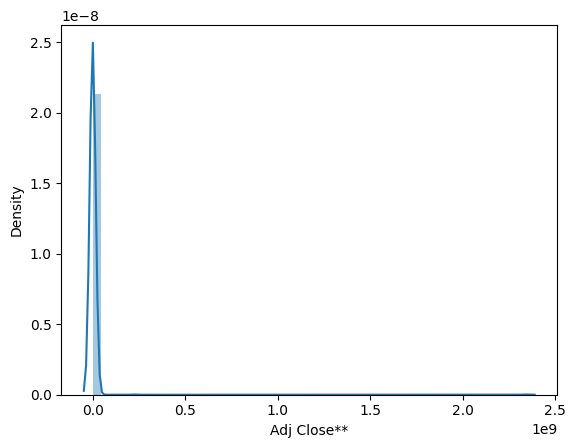

In [6]:
sns.distplot(dataset["Adj Close**"])

C:\Users\junai\AppData\Local\Temp\ipykernel_15680\2012513486.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Volume"])


<Axes: xlabel='Volume', ylabel='Density'>

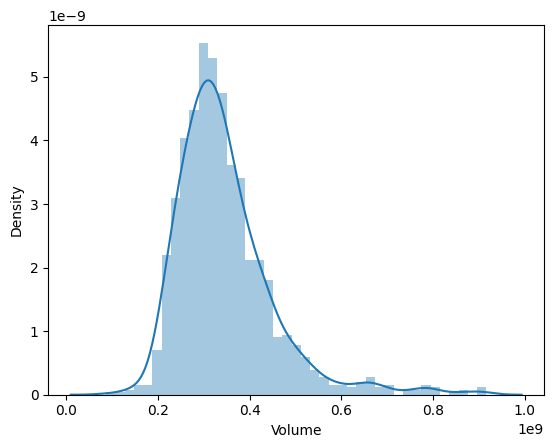

In [7]:
sns.distplot(dataset["Volume"])

In [8]:
dataset.describe()

,Open,High,Low,Close*,Adj Close**,Volume
count,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03,1.258000e+03
mean,29596.153545,29776.945739,29402.470660,29599.361677,2.067919e+06,3.450636e+08
std,4006.408015,4009.007573,4004.990359,4007.468822,6.632463e+07,1.069142e+08
min,19028.360000,19121.010000,18213.650000,18591.930000,2.300000e+01,8.615000e+07
25%,26041.267500,26163.155000,25877.872500,26027.120000,2.602530e+04,2.773125e+08
50%,29201.410000,29335.685000,28996.500000,29199.460000,2.919115e+04,3.247250e+08
75%,33618.672500,33825.445000,33346.827500,33600.342500,3.361139e+04,3.875100e+08
max,36722.600000,36952.650000,36636.000000,36799.650000,2.342111e+09,9.159900e+08


In [9]:
#there is huge magnitude difference between magnitude in Adj Close** and Volume
#therefore doing feature scaling using sklearn
from sklearn.preprocessing import StandardScaler

In [11]:
ss = StandardScaler()
ss.fit(dataset[["Adj Close**"]])

StandardScaler()

In [14]:
dataset["Adj Close**_ss"]= pd.DataFrame( ss.transform(dataset[["Adj Close**"]]),columns=["x"])
dataset.head(5)

,Date,Open,High,Low,Close*,Adj Close**,Volume,Adj Close**_ss
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000,-0.030677
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000,-0.030681
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000,-0.030689
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000,-0.031191
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000,-0.030680


In [15]:
dataset.describe()

,Open,High,Low,Close*,Adj Close**,Volume,Adj Close**_ss
count,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03,1.258000e+03,1.258000e+03
mean,29596.153545,29776.945739,29402.470660,29599.361677,2.067919e+06,3.450636e+08,2.824097e-18
std,4006.408015,4009.007573,4004.990359,4007.468822,6.632463e+07,1.069142e+08,1.000398e+00
min,19028.360000,19121.010000,18213.650000,18591.930000,2.300000e+01,8.615000e+07,-3.119080e-02
25%,26041.267500,26163.155000,25877.872500,26027.120000,2.602530e+04,2.773125e+08,-3.079860e-02
50%,29201.410000,29335.685000,28996.500000,29199.460000,2.919115e+04,3.247250e+08,-3.075085e-02
75%,33618.672500,33825.445000,33346.827500,33600.342500,3.361139e+04,3.875100e+08,-3.068417e-02
max,36722.600000,36952.650000,36636.000000,36799.650000,2.342111e+09,9.159900e+08,3.529570e+01


C:\Users\junai\AppData\Local\Temp\ipykernel_15680\2997273002.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Adj Close**"])
C:\Users\junai\AppData\Local\Temp\ipykernel_15680\2997273002.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Adj Close**_ss"])


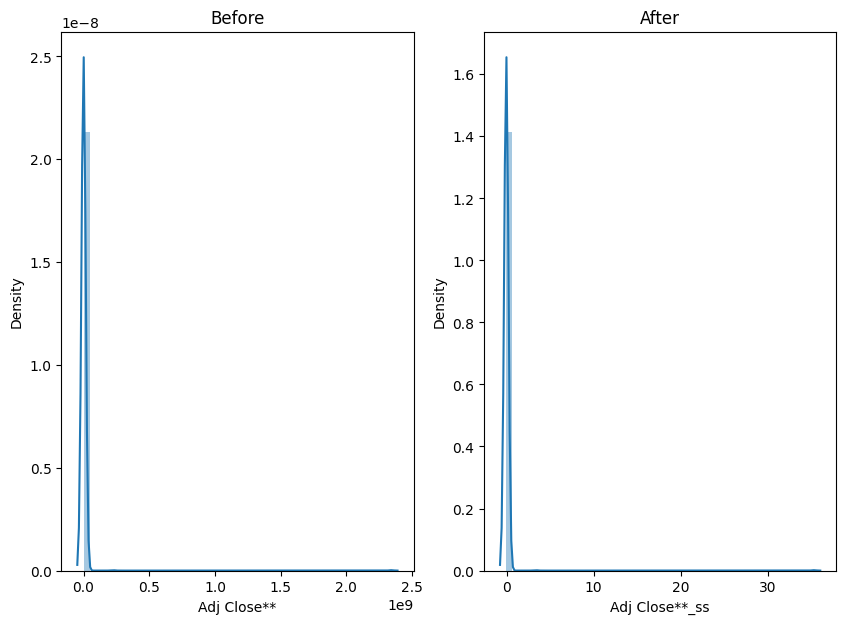

In [18]:
plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.title("Before")
sns.distplot(dataset["Adj Close**"])

plt.subplot(1,2,2)
plt.title("After")
sns.distplot(dataset["Adj Close**_ss"])
plt.show()

The scale of the data has reduced but the magnitude remains same 

### Normalization
#### Min-Max Scaling

Xnew = ( Xi - min(X)) /( max(x) - min(X))

data always lies between 0 and 1

In [19]:
dataset = pd.read_excel(r"C:\Users\junai\Desktop\coding\ML\yahoo_data.xlsx")
dataset.head(5)

,Date,Open,High,Low,Close*,Adj Close**,Volume
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000


In [20]:
dataset.isnull().sum()

Date           0
Open           0
High           0
Low            0
Close*         0
Adj Close**    0
Volume         0
dtype: int64

In [21]:
dataset.describe()

,Open,High,Low,Close*,Adj Close**,Volume
count,1258.000000,1258.000000,1258.000000,1258.000000,1.258000e+03,1.258000e+03
mean,29596.153545,29776.945739,29402.470660,29599.361677,2.067919e+06,3.450636e+08
std,4006.408015,4009.007573,4004.990359,4007.468822,6.632463e+07,1.069142e+08
min,19028.360000,19121.010000,18213.650000,18591.930000,2.300000e+01,8.615000e+07
25%,26041.267500,26163.155000,25877.872500,26027.120000,2.602530e+04,2.773125e+08
50%,29201.410000,29335.685000,28996.500000,29199.460000,2.919115e+04,3.247250e+08
75%,33618.672500,33825.445000,33346.827500,33600.342500,3.361139e+04,3.875100e+08
max,36722.600000,36952.650000,36636.000000,36799.650000,2.342111e+09,9.159900e+08


C:\Users\junai\AppData\Local\Temp\ipykernel_15680\3799357775.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Volume"])


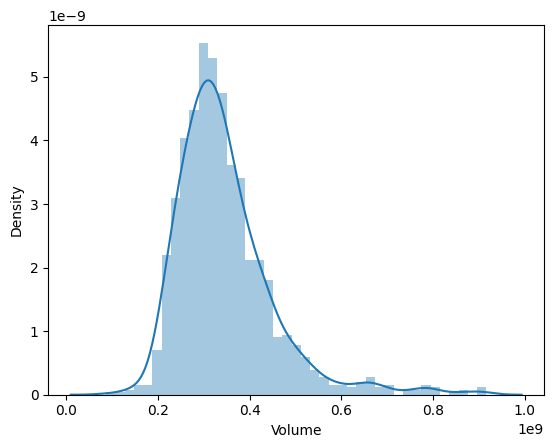

In [22]:
# using min max scaling on Volume to compress data
sns.distplot(dataset["Volume"])
plt.show()

In [25]:
from sklearn.preprocessing import MinMaxScaler

In [27]:
mms = MinMaxScaler()
mms.fit(dataset[["Volume"]])

MinMaxScaler()

In [29]:
dataset["Volume_mms"] = mms.transform(dataset[["Volume"]])
dataset.head(5)

,Date,Open,High,Low,Close*,Adj Close**,Volume,Volume_mms
0,"Apr 28, 2023",33797.43,34104.56,33728.40,34098.16,34098.16,354310000,0.323147
1,"Apr 27, 2023",33797.43,33859.75,33374.65,33826.16,33826.16,343240000,0.309807
2,"Apr 26, 2023",33596.34,33645.83,33235.85,33301.87,33301.87,321170000,0.283211
3,"Apr 25, 2023",33828.34,33875.49,33525.39,33530.83,33.00,297880000,0.255146
4,"Apr 24, 2023",33805.04,33891.15,33726.09,33875.40,33875.40,252020000,0.199882


C:\Users\junai\AppData\Local\Temp\ipykernel_15680\472535027.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Volume"])
C:\Users\junai\AppData\Local\Temp\ipykernel_15680\472535027.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset["Volume_mms"])


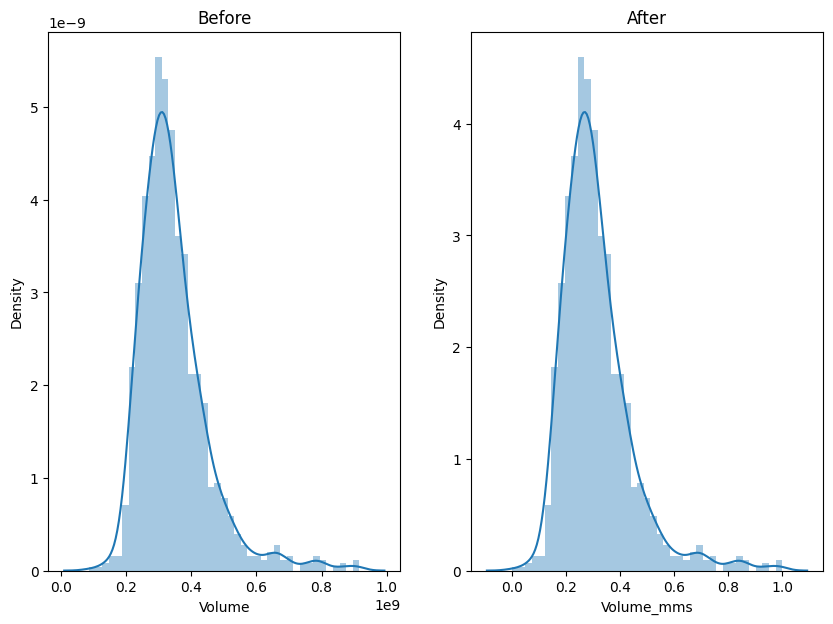

In [30]:
plt.figure(figsize=(10,7))
plt.subplot(1,2,1)
plt.title("Before")
sns.distplot(dataset["Volume"])

plt.subplot(1,2,2)
plt.title("After")
sns.distplot(dataset["Volume_mms"])
plt.show()

the min max value of data is compressed between 0 to 1 , but the magnitude remains same 